# Comparison: `ppc_gwtc5_k5_short`, `ppc_gwtc5_k10_short`, `ppc_gwtc5_k10_split_short`

Each run uses its own chain as it is on disk (re-run the notebook to pick up chains that have grown). Masses are
windowed ($m_2 > 3\,M_\odot$) before any marginal is taken; spin quantities are the windowed population marginal and
the conditional's per-$(m_1, q)$ moments, read from the chain or rebuilt from the spin field (`notebooks/analysis.py`,
printed per run). Bands are 90% over draws; lines are medians. The runs are independent chains, so differences are
read from whether the bands overlap, not from draw-by-draw differences.

In [1]:
import os
os.environ.setdefault('JAX_PLATFORMS', 'cpu')
os.environ.setdefault('XLA_FLAGS', '--xla_cpu_multi_thread_eigen=false intra_op_parallelism_threads=1')
for v in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS'):
    os.environ.setdefault(v, '1')
import sys
REPO = '/home/jack.heinzel/public_html/bbh-pixelpop-constraints'
sys.path.insert(0, REPO); sys.path.insert(0, os.path.join(REPO, 'notebooks'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pixelpop                     # switches matplotlib to Agg on import, so before %matplotlib inline
%matplotlib inline
import plot_style
plot_style.apply()
import analysis as A
from analysis import band, fmt
from model import SPIN_REF_MASSES

RUNS = ['ppc_gwtc5_k5_short', 'ppc_gwtc5_k10_short', 'ppc_gwtc5_k10_split_short']
NAME = 'gwtc5_field_vs_split'
R = {}
for run in RUNS:
    r = A.load_run(run)
    R[run] = r
    print(f'{run}: {r.spin_model} model, k = {r.k}, {r.n_chains} chain(s) x {r.n_draws} draws; spins {r.spin_source}'
          + (f' (rebuild vs saved marginal, max total variation {r.rebuild_tv:.1e})' if r.rebuild_tv is not None else ''))
COL = {run: f'C{i}' for i, run in enumerate(RUNS)}
LS = {run: '-' if i == 0 else '--' for i, run in enumerate(RUNS)}
LAB = {run: run.replace('ppc_', '').replace('_', r'\_') for run in RUNS}

ppc_gwtc5_k5_short: field model, k = 5, 1 chain(s) x 500 draws; spins rebuilt from the saved spin latents on 150 of 500 draws per chain (rebuild vs saved marginal, max total variation 1.9e-03)


ppc_gwtc5_k10_short: field model, k = 10, 1 chain(s) x 500 draws; spins rebuilt from the saved spin latents on 150 of 500 draws per chain (rebuild vs saved marginal, max total variation 2.9e-03)


ppc_gwtc5_k10_split_short: split model, k = 10, 1 chain(s) x 500 draws; spins rebuilt from the saved spin latents on 150 of 500 draws per chain (rebuild vs saved marginal, max total variation 2.2e-03)


## Convergence and fit

In [2]:
def cell(df, k):
    if k not in df.index:
        return ''
    r = df.loc[k]
    return f"{r['median']:.3f} [{r['lo5']:.3f}, {r['hi95']:.3f}]  (ESS {r['ess']:.0f}, R-hat {r['rhat']:.3f})"
keys = []
for run in RUNS:
    keys += [k for k in R[run].summary.index if k not in keys]
pd.set_option('display.max_colwidth', 80)
pd.DataFrame({run: [cell(R[run].summary, k) for k in keys] for run in RUNS}, index=keys)

,ppc_gwtc5_k5_short,ppc_gwtc5_k10_short,ppc_gwtc5_k10_split_short
lnsigma,"1.041 [0.677, 1.488] (ESS 196, R-hat 1.003)","1.049 [0.645, 1.502] (ESS 114, R-hat 0.999)","1.030 [0.645, 1.488] (ESS 174, R-hat 0.998)"
log_nu_spde,"0.334 [-0.220, 0.981] (ESS 321, R-hat 1.013)","0.321 [-0.285, 0.966] (ESS 285, R-hat 1.000)","0.290 [-0.310, 0.967] (ESS 211, R-hat 1.000)"
log_ranges[ln m1],"2.887 [2.418, 3.477] (ESS 208, R-hat 0.998)","2.937 [2.398, 3.580] (ESS 92, R-hat 1.012)","2.968 [2.466, 3.628] (ESS 88, R-hat 1.019)"
log_ranges[q],"4.295 [3.763, 4.568] (ESS 256, R-hat 0.999)","4.293 [3.789, 4.576] (ESS 157, R-hat 0.998)","4.344 [3.852, 4.575] (ESS 247, R-hat 0.998)"
lnsigma_spin,"1.298 [0.871, 1.763] (ESS 177, R-hat 1.003)","1.315 [0.920, 1.833] (ESS 125, R-hat 1.000)",
log_nu_spin,"0.517 [-0.190, 1.244] (ESS 294, R-hat 0.998)","0.655 [0.077, 1.342] (ESS 234, R-hat 0.998)",
log_ranges_spin[ln m1 mode],"4.390 [3.921, 4.591] (ESS 356, R-hat 1.002)","4.413 [3.879, 4.589] (ESS 231, R-hat 0.998)",
log_ranges_spin[q mode],"4.435 [4.017, 4.593] (ESS 311, R-hat 1.004)","4.476 [4.138, 4.591] (ESS 306, R-hat 0.999)",
log_ranges_spin[chi_eff],"3.181 [2.722, 3.606] (ESS 252, R-hat 1.003)","3.158 [2.765, 3.593] (ESS 241, R-hat 1.004)",
log_ranges_spin[chi_p],"3.899 [3.380, 4.356] (ESS 254, R-hat 1.011)","3.883 [3.419, 4.276] (ESS 291, R-hat 1.001)",


Saved /home/jack.heinzel/public_html/bbh-pixelpop-constraints/plots/compare_gwtc5_field_vs_split_traces.pdf


'/home/jack.heinzel/public_html/bbh-pixelpop-constraints/plots/compare_gwtc5_field_vs_split_traces.pdf'

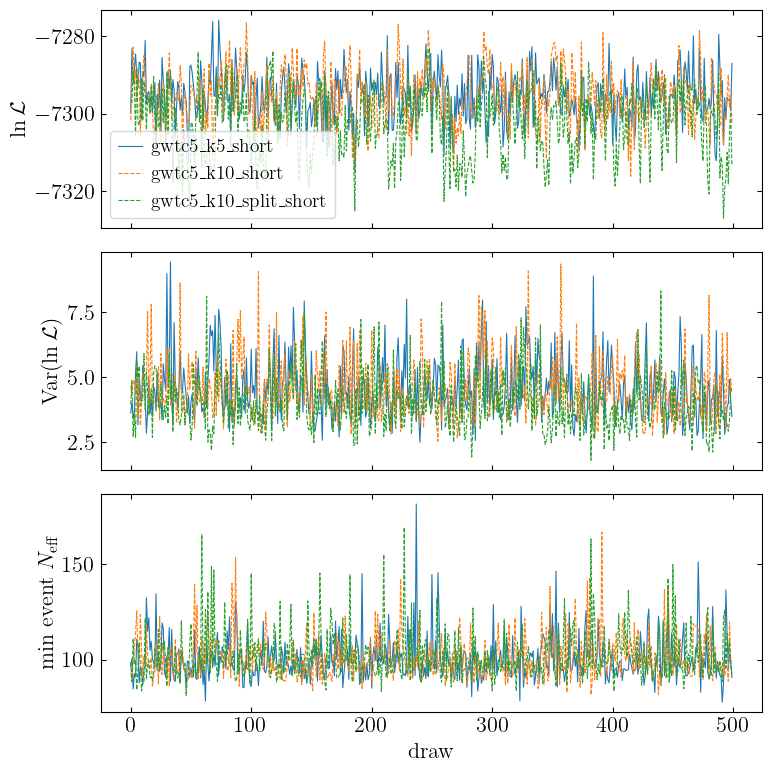

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(8, 8), sharex=True)
for run in RUNS:
    S = R[run].S
    for c in range(S['log_likelihood'].shape[0]):
        for ax, y in zip(axes, (S['log_likelihood'][c], S['log_likelihood_variance'][c], S['event_neff'][c].min(-1))):
            ax.plot(y, lw=0.8, color=COL[run], ls=LS[run], label=LAB[run] if (c == 0 and ax is axes[0]) else None)
for ax, lab in zip(axes, (r'$\ln \mathcal{L}$', r'$\mathrm{Var}(\ln \mathcal{L})$', r'min event $N_\mathrm{eff}$')):
    ax.set_ylabel(lab)
axes[0].legend(**plot_style.LEG_KW); axes[-1].set_xlabel('draw')
fig.tight_layout(); plot_style.save(fig, f'compare_{NAME}_traces')

In [4]:
n = 10
worst = {run: R[run].neff.sort_values('median').head(n) for run in RUNS}
pd.concat({run: w[['median', 'frac < 100']].reset_index().rename(columns={'index': 'event'}) for run, w in worst.items()},
          axis=1).round(2)

ppc_gwtc5_k5_short                        ppc_gwtc5_k10_short              \
               event      median frac < 100               event      median   
0    GW191127_050227  117.690002       0.18     GW191127_050227  118.180000   
1    GW200216_220804  121.720001       0.15     GW200216_220804  120.220001   
2    GW240526_093944  127.570000       0.17     GW240526_093944  129.720001   
3    GW190805_211137  166.740005       0.06     GW241116_151753  175.179993   
4    GW241116_151753  174.660004       0.03     GW190805_211137  175.559998   
5    GW240618_071627  182.380005       0.04     GW240618_071627  191.360001   
6    GW240107_013215  216.360001       0.02     GW241114_024711  214.100006   
7    GW241114_024711  216.850006       0.00     GW240107_013215  218.479996   
8    GW191230_180458  233.210007       0.00     GW230630_125806  234.210007   
9    GW231230_170116  237.949997       0.01     GW191230_180458  237.600006   

             ppc_gwtc5_k10_split_short                         
  frac < 100                     event      median frac < 100  
0       0.18           GW191127_050227  115.779999       0.20  
1       0.13           GW200216_220804  119.570000       0.14  
2       0.18           GW240526_093944  128.589996       0.17  
3       0.03           GW241116_151753  167.940002       0.03  
4       0.04           GW190805_211137  172.570007       0.05  
5       0.01           GW240107_013215  188.149994       0.02  
6       0.01           GW240618_071627  200.300003       0.02  
7       0.01           GW241114_024711  204.990005       0.01  
8       0.00           GW191230_180458  218.559998       0.01  
9       0.00           GW231230_170116  228.940002       0.02

## Masses

Saved /home/jack.heinzel/public_html/bbh-pixelpop-constraints/plots/compare_gwtc5_field_vs_split_mass_marginals.pdf


'/home/jack.heinzel/public_html/bbh-pixelpop-constraints/plots/compare_gwtc5_field_vs_split_mass_marginals.pdf'

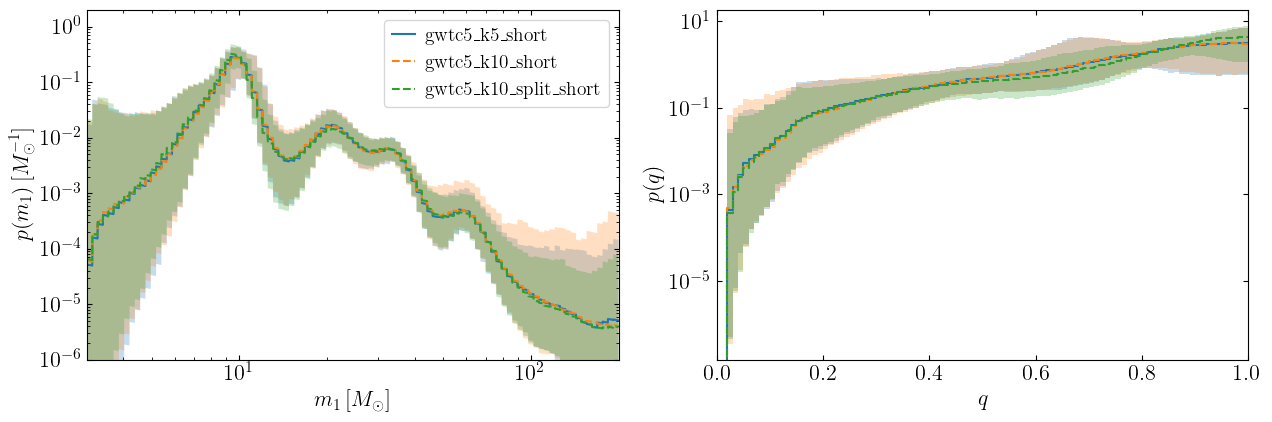

In [5]:
N_FINE = 50
m_edges = np.exp(A.lnm_edges)
m_fine = np.concatenate([np.linspace(a, b, N_FINE, endpoint=False) for a, b in zip(m_edges[:-1], m_edges[1:])])
idx_fine = np.repeat(np.arange(A.B), N_FINE)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for run in RUNS:
    r = R[run]
    lo, med, hi = band(r.p_lnm[:, idx_fine] / m_fine[None])
    axes[0].fill_between(m_fine, lo, hi, color=COL[run], alpha=0.25, lw=0)
    axes[0].plot(m_fine, med, color=COL[run], ls=LS[run], label=LAB[run])
    lo, med, hi = band(np.concatenate([r.p_q, r.p_q[:, -1:]], 1))
    axes[1].fill_between(A.q_edges, lo, hi, step='post', color=COL[run], alpha=0.25, lw=0)
    axes[1].step(A.q_edges, med, where='post', color=COL[run], ls=LS[run])
axes[0].set_xscale('log'); axes[0].set_yscale('log'); axes[0].set_xlim(A.MIN_M, A.MAX_M)
axes[0].set_ylim(1e-6, 2); axes[0].set_xlabel(r'$m_1\,[M_\odot]$'); axes[0].set_ylabel(r'$p(m_1)\,[M_\odot^{-1}]$')
axes[0].legend(**plot_style.LEG_KW)
axes[1].set_yscale('log'); axes[1].set_xlim(0, 1); axes[1].set_xlabel(r'$q$'); axes[1].set_ylabel(r'$p(q)$')
fig.tight_layout(); plot_style.save(fig, f'compare_{NAME}_mass_marginals')

Saved /home/jack.heinzel/public_html/bbh-pixelpop-constraints/plots/compare_gwtc5_field_vs_split_m1_given_q.pdf
share of the population in each q range, median [5%, 95%]


,ppc_gwtc5_k5_short,ppc_gwtc5_k10_short,ppc_gwtc5_k10_split_short
0.1 < q < 0.4,"0.047 [0.015, 0.121]","0.044 [0.014, 0.124]","0.044 [0.017, 0.099]"
0.4 < q < 0.6,"0.100 [0.051, 0.197]","0.100 [0.052, 0.193]","0.083 [0.041, 0.157]"
0.6 < q < 0.8,"0.246 [0.103, 0.639]","0.251 [0.099, 0.622]","0.192 [0.078, 0.417]"
0.8 < q < 1,"0.593 [0.149, 0.784]","0.587 [0.167, 0.782]","0.671 [0.376, 0.815]"


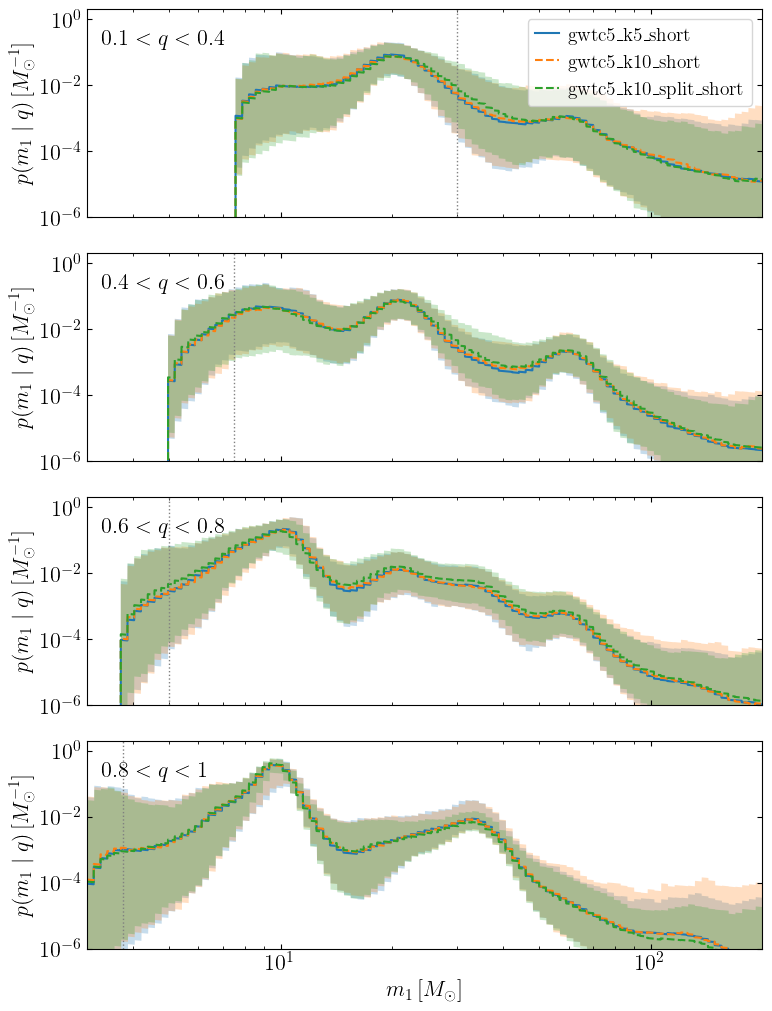

In [6]:
Q_RANGES = [(0.1, 0.4), (0.4, 0.6), (0.6, 0.8), (0.8, 1.0)]
fig, axes = plt.subplots(len(Q_RANGES), 1, figsize=(8, 2.6 * len(Q_RANGES)), sharex=True)
rows = {}
for ax, (qlo, qhi) in zip(axes, Q_RANGES):
    sel = (A.q_edges[:-1] >= qlo - 1e-9) & (A.q_edges[1:] <= qhi + 1e-9)
    for run in RUNS:
        p = R[run].p_mass[:, :, sel].sum(2) * A.dq
        share = p.sum(1) * A.dlnm
        rows.setdefault(f'{qlo:g} < q < {qhi:g}', {})[run] = fmt(share)
        lo, med, hi = band((p / share[:, None])[:, idx_fine] / m_fine[None])
        ax.fill_between(m_fine, lo, hi, color=COL[run], alpha=0.25, lw=0)
        ax.plot(m_fine, med, color=COL[run], ls=LS[run], label=LAB[run])
    ax.axvline(A.MIN_M / qlo, color='0.5', ls=':', lw=1)
    ax.text(0.02, 0.9, rf'${qlo:g} < q < {qhi:g}$', transform=ax.transAxes, va='top')
    ax.set_yscale('log'); ax.set_ylim(1e-6, 2); ax.set_ylabel(r'$p(m_1 \mid q)\,[M_\odot^{-1}]$')
axes[0].legend(loc='upper right', **plot_style.LEG_KW)
axes[-1].set_xscale('log'); axes[-1].set_xlim(A.MIN_M, A.MAX_M); axes[-1].set_xlabel(r'$m_1\,[M_\odot]$')
fig.tight_layout(); plot_style.save(fig, f'compare_{NAME}_m1_given_q')
print('share of the population in each q range, median [5%, 95%]')
pd.DataFrame(rows).T

### Masses in $\chi_\mathrm{eff}$ slices

$p(m_1 \mid \chi_\mathrm{eff} \in S)$ and $p(q \mid \chi_\mathrm{eff} \in S)$, from
$p(\ln m_1, q \mid S) \propto p(\ln m_1, q)\, P(\chi_\mathrm{eff} \in S \mid m_1, q)$ with the windowed mass
distribution and the spin conditional of each draw. The slices overlap: $0 < \chi_\mathrm{eff} < 0.1$ is inside
$|\chi_\mathrm{eff}| < 0.2$. The table gives each slice's share of the population, $P(\chi_\mathrm{eff} \in S)$.

Saved /home/jack.heinzel/public_html/bbh-pixelpop-constraints/plots/compare_gwtc5_field_vs_split_mass_given_chieff.pdf
share of the population in each chi_eff slice, median [5%, 95%]


,ppc_gwtc5_k5_short,ppc_gwtc5_k10_short,ppc_gwtc5_k10_split_short
0 < chi_eff < 0.1,"0.500 [0.378, 0.579]","0.495 [0.364, 0.580]","0.495 [0.406, 0.602]"
|chi_eff| < 0.2,"0.914 [0.716, 0.955]","0.909 [0.647, 0.958]","0.928 [0.848, 0.967]"
|chi_eff| > 0.2,"0.086 [0.045, 0.284]","0.091 [0.042, 0.353]","0.072 [0.033, 0.152]"


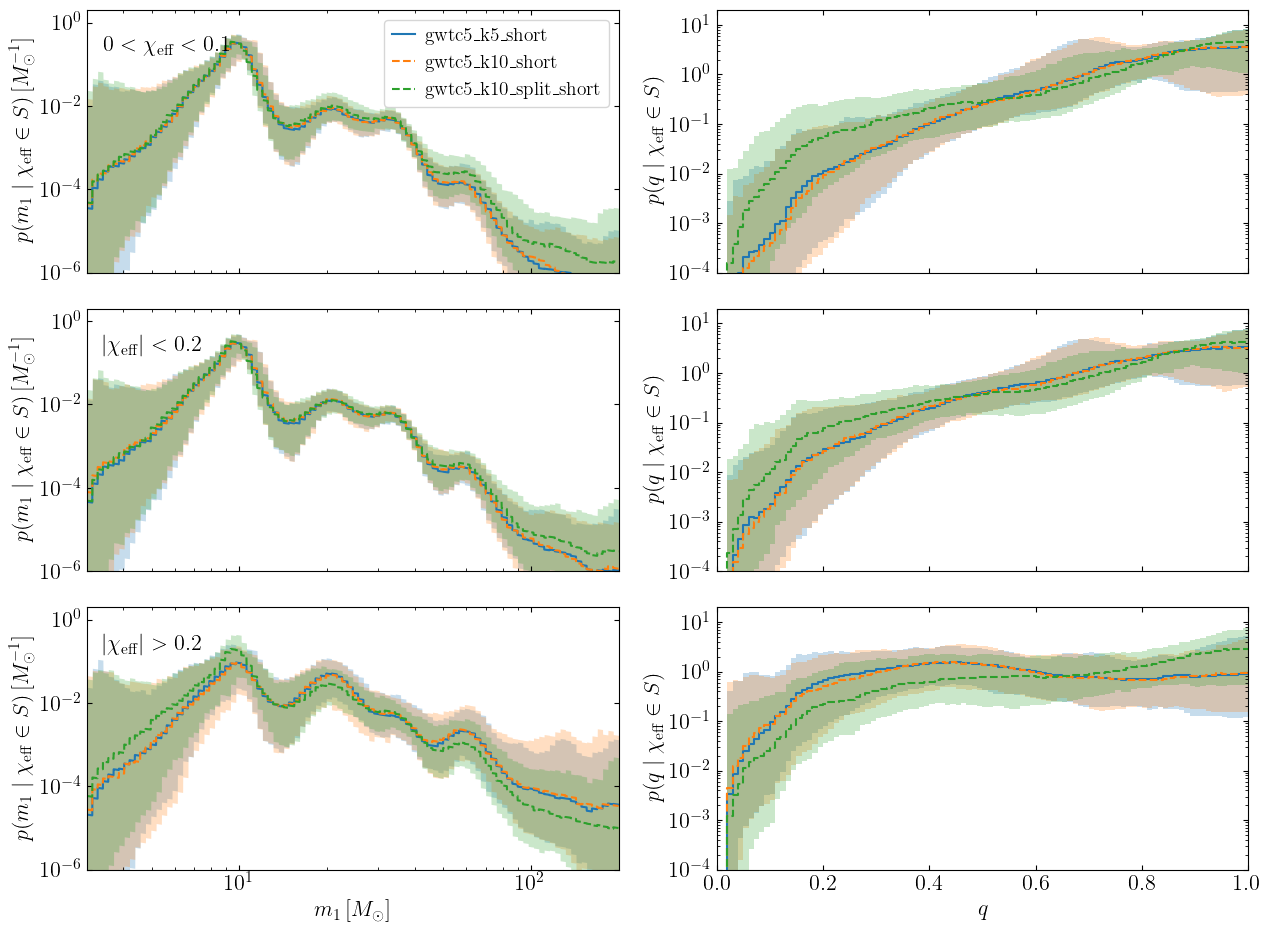

In [7]:
SL = list(A.CHI_EFF_SLICES)
fig, axes = plt.subplots(len(SL), 2, figsize=(13, 3.2 * len(SL)), sharex='col')
for j, lab in enumerate(SL):
    for run in RUNS:
        pms = R[run].p_mass_slice[..., j]                                      # (draws, ln m1, q)
        p_lnm = pms.sum(2) * A.dq; p_q = pms.sum(1) * A.dlnm
        lo, med, hi = band(p_lnm[:, idx_fine] / m_fine[None])
        axes[j, 0].fill_between(m_fine, lo, hi, color=COL[run], alpha=0.25, lw=0)
        axes[j, 0].plot(m_fine, med, color=COL[run], ls=LS[run], label=LAB[run])
        lo, med, hi = band(np.concatenate([p_q, p_q[:, -1:]], 1))
        axes[j, 1].fill_between(A.q_edges, lo, hi, step='post', color=COL[run], alpha=0.25, lw=0)
        axes[j, 1].step(A.q_edges, med, where='post', color=COL[run], ls=LS[run])
    axes[j, 0].text(0.03, 0.9, f'${lab}$', transform=axes[j, 0].transAxes, va='top')
    axes[j, 0].set_xscale('log'); axes[j, 0].set_yscale('log'); axes[j, 0].set_ylim(1e-6, 2)
    axes[j, 0].set_ylabel(r'$p(m_1 \mid \chi_\mathrm{eff} \in S)\,[M_\odot^{-1}]$')
    axes[j, 1].set_yscale('log'); axes[j, 1].set_ylim(1e-4, 20)
    axes[j, 1].set_ylabel(r'$p(q \mid \chi_\mathrm{eff} \in S)$')
axes[0, 0].legend(loc='upper right', **plot_style.LEG_KW)
axes[-1, 0].set_xlim(A.MIN_M, A.MAX_M); axes[-1, 0].set_xlabel(r'$m_1\,[M_\odot]$')
axes[-1, 1].set_xlim(0, 1); axes[-1, 1].set_xlabel(r'$q$')
fig.tight_layout(); plot_style.save(fig, f'compare_{NAME}_mass_given_chieff')
print('share of the population in each chi_eff slice, median [5%, 95%]')
PLAIN = ['0 < chi_eff < 0.1', '|chi_eff| < 0.2', '|chi_eff| > 0.2']
pd.DataFrame({run: {PLAIN[j]: fmt(R[run].slice_share[:, j]) for j in range(len(SL))} for run in RUNS})

## Spins: the population marginal (windowed)

Saved /home/jack.heinzel/public_html/bbh-pixelpop-constraints/plots/compare_gwtc5_field_vs_split_spin_marginal.pdf
population spin moments (windowed), median [5%, 95%]


,ppc_gwtc5_k5_short,ppc_gwtc5_k10_short,ppc_gwtc5_k10_split_short
mean chi_eff,"0.037 [-0.109, 0.066]","0.033 [-0.204, 0.063]","0.036 [-0.012, 0.060]"
sd chi_eff,"0.145 [0.099, 0.393]","0.144 [0.103, 0.437]","0.121 [0.091, 0.254]"
P(chi_eff < 0),"0.295 [0.201, 0.434]","0.297 [0.203, 0.462]","0.311 [0.194, 0.414]"
mean chi_p,"0.227 [0.180, 0.280]","0.223 [0.168, 0.284]","0.259 [0.196, 0.316]"


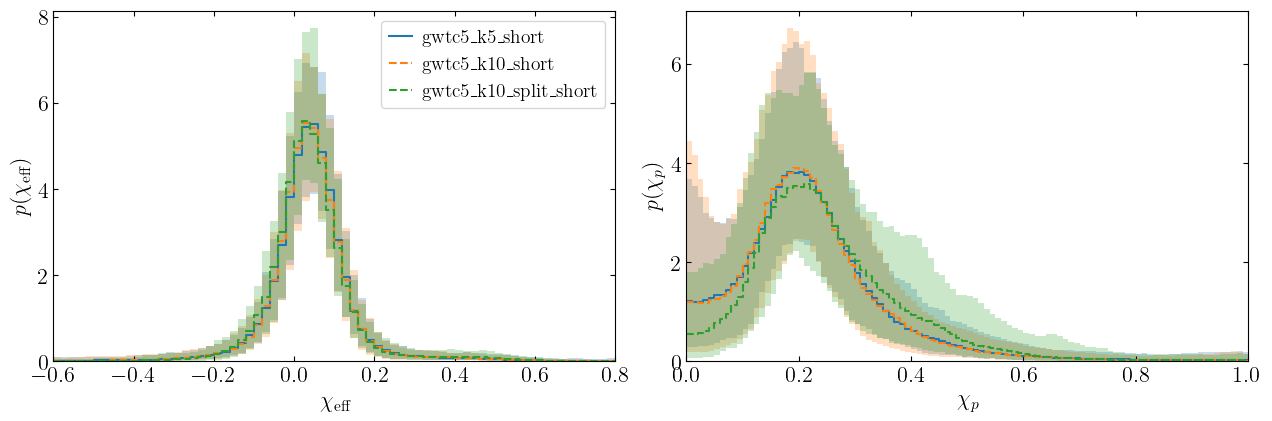

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for run in RUNS:
    for ax, y, edges in zip(axes, A.spin_1d(R[run].P_win), (A.e_edges, A.p_edges)):
        lo, med, hi = band(np.concatenate([y, y[:, -1:]], 1))
        ax.fill_between(edges, lo, hi, step='post', color=COL[run], alpha=0.25, lw=0)
        ax.step(edges, med, where='post', color=COL[run], ls=LS[run], label=LAB[run])
for ax, edges, lab in ((axes[0], A.e_edges, r'\chi_\mathrm{eff}'), (axes[1], A.p_edges, r'\chi_p')):
    ax.set_xlim(edges[0], edges[-1]); ax.set_ylim(0); ax.set_xlabel(rf'${lab}$'); ax.set_ylabel(rf'$p({lab})$')
axes[0].set_xlim(-0.6, 0.8); axes[0].legend(**plot_style.LEG_KW)
fig.tight_layout(); plot_style.save(fig, f'compare_{NAME}_spin_marginal')
tabs = {run: A.spin_moments_table(R[run].P_win).apply(fmt) for run in RUNS}
print('population spin moments (windowed), median [5%, 95%]')
pd.DataFrame(tabs)

Saved /home/jack.heinzel/public_html/bbh-pixelpop-constraints/plots/compare_gwtc5_field_vs_split_spin_joint.pdf


'/home/jack.heinzel/public_html/bbh-pixelpop-constraints/plots/compare_gwtc5_field_vs_split_spin_joint.pdf'

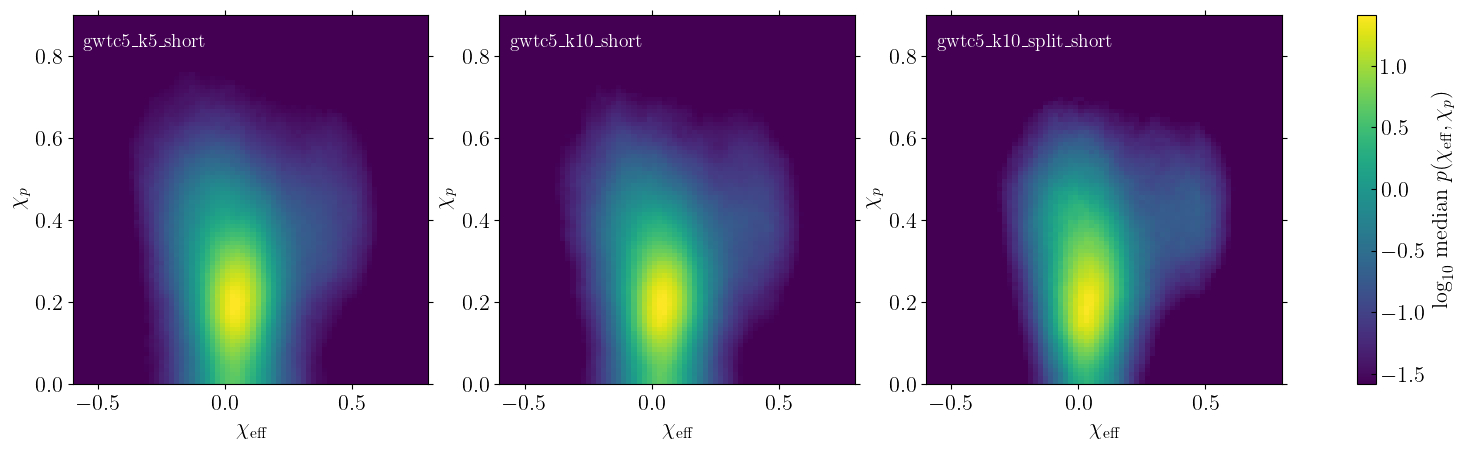

In [9]:
fig, axes = plt.subplots(1, len(RUNS), figsize=(6.5 * len(RUNS), 4.8), squeeze=False)
meds = {run: np.median(R[run].P_win, 0) / (A.de * A.dp) for run in RUNS}
vmax = np.log10(max(m.max() for m in meds.values())); vmin = vmax - 3
for ax, run in zip(axes[0], RUNS):
    pc = ax.pcolormesh(A.e_edges, A.p_edges, np.log10(np.maximum(meds[run], 1e-300)).T, vmin=vmin, vmax=vmax,
                       cmap='viridis', shading='flat', rasterized=True)
    ax.tick_params(which='both', direction='out')
    ax.set_xlabel(r'$\chi_\mathrm{eff}$'); ax.set_ylabel(r'$\chi_p$'); ax.set_xlim(-0.6, 0.8); ax.set_ylim(0, 0.9)
    ax.text(0.03, 0.95, LAB[run], transform=ax.transAxes, va='top', color='w', fontsize=14)
cb = fig.colorbar(pc, ax=axes[0].tolist()); cb.set_label(r'$\log_{10}$ median $p(\chi_\mathrm{eff}, \chi_p)$')
plot_style.save(fig, f'compare_{NAME}_spin_joint')

## Spin moments as a function of primary mass

The conditional's mean and sd of $\chi_\mathrm{eff}$ and $\chi_p$ in every $m_1$ bin, first at $q \approx 1$ (the top
$q$ bin), then in $q$ slices (one row per slice). Bins with $q\,m_1 < 3\,M_\odot$ are dropped. With no data, the field
relaxes towards a flat density on the physical region: mean $\chi_\mathrm{eff} = 0$, sd $\chi_\mathrm{eff} \approx 0.52$,
mean $\chi_p \approx 0.46$, sd $\chi_p \approx 0.28$.

Saved /home/jack.heinzel/public_html/bbh-pixelpop-constraints/plots/compare_gwtc5_field_vs_split_spin_moments_q1.pdf
q ~ 1: median [5%, 95%] over draws


ppc_gwtc5_k5_short    ppc_gwtc5_k10_short  \
10 Msun mean chi_eff  0.046 [-0.038, 0.071]   0.040 [0.001, 0.079]   
        sd chi_eff     0.073 [0.050, 0.260]   0.076 [0.050, 0.199]   
        mean chi_p     0.206 [0.143, 0.279]   0.208 [0.147, 0.275]   
        sd chi_p       0.087 [0.050, 0.156]   0.085 [0.046, 0.151]   
20 Msun mean chi_eff   0.032 [0.000, 0.068]  0.033 [-0.009, 0.065]   
        sd chi_eff     0.081 [0.056, 0.160]   0.082 [0.057, 0.154]   
        mean chi_p     0.250 [0.183, 0.325]   0.241 [0.186, 0.327]   
        sd chi_p       0.100 [0.060, 0.148]   0.098 [0.059, 0.146]   
35 Msun mean chi_eff  0.014 [-0.049, 0.045]  0.017 [-0.057, 0.045]   
        sd chi_eff     0.109 [0.073, 0.279]   0.112 [0.079, 0.280]   
        mean chi_p     0.293 [0.200, 0.368]   0.287 [0.214, 0.388]   
        sd chi_p       0.122 [0.080, 0.167]   0.125 [0.089, 0.173]   
60 Msun mean chi_eff  0.024 [-0.628, 0.242]  0.027 [-0.895, 0.192]   
        sd chi_eff     0.192 [0.097, 0.364]   0.177 [0.088, 0.382]   
        mean chi_p     0.372 [0.113, 0.581]   0.379 [0.074, 0.525]   
        sd chi_p       0.161 [0.077, 0.263]   0.169 [0.076, 0.260]   

                     ppc_gwtc5_k10_split_short  
10 Msun mean chi_eff      0.039 [0.010, 0.072]  
        sd chi_eff        0.095 [0.060, 0.180]  
        mean chi_p        0.238 [0.163, 0.301]  
        sd chi_p          0.121 [0.073, 0.185]  
20 Msun mean chi_eff     0.031 [-0.036, 0.079]  
        sd chi_eff        0.118 [0.066, 0.280]  
        mean chi_p        0.265 [0.195, 0.348]  
        sd chi_p          0.133 [0.088, 0.199]  
35 Msun mean chi_eff     0.021 [-0.026, 0.055]  
        sd chi_eff        0.114 [0.071, 0.178]  
        mean chi_p        0.278 [0.220, 0.357]  
        sd chi_p          0.127 [0.091, 0.195]  
60 Msun mean chi_eff     0.032 [-0.132, 0.122]  
        sd chi_eff        0.157 [0.091, 0.301]  
        mean chi_p        0.314 [0.205, 0.431]  
        sd chi_p          0.150 [0.091, 0.229]

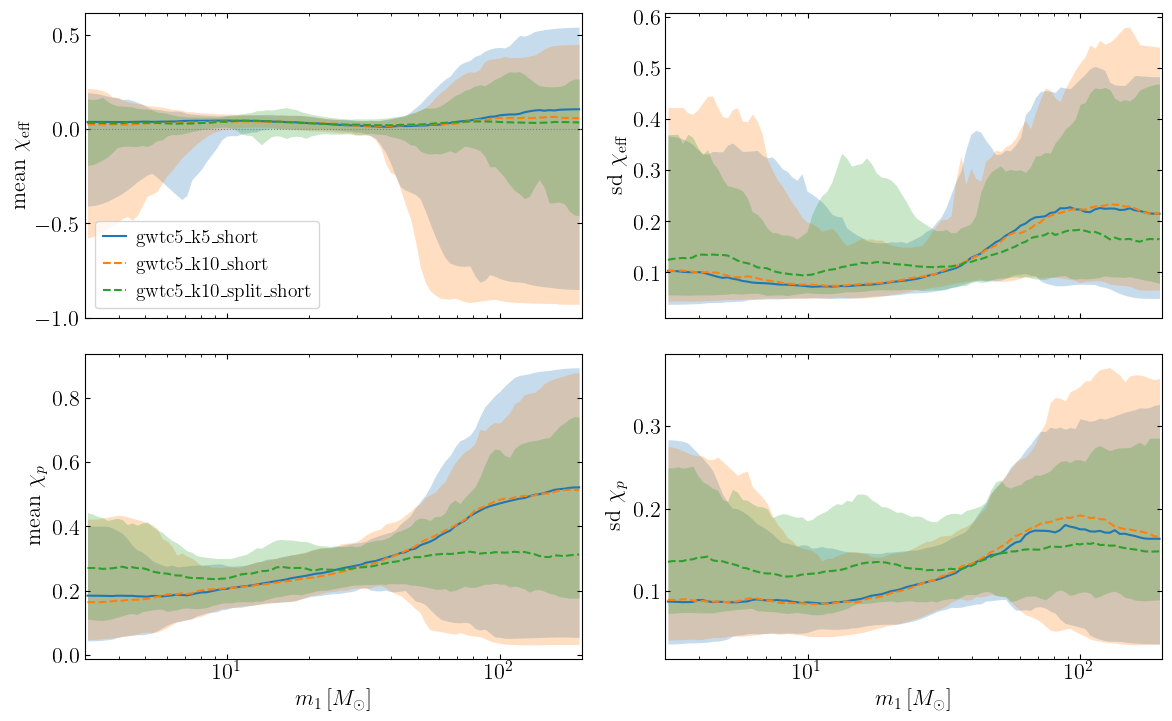

In [10]:
MOM_LABELS = [r'mean $\chi_\mathrm{eff}$', r'sd $\chi_\mathrm{eff}$', r'mean $\chi_p$', r'sd $\chi_p$']

def moment_panels(axes, run, iq, label=None):
    ok = A.q_c[iq] * A.m_c >= A.MIN_M
    for k, ax in enumerate(axes):
        lo, med, hi = band(R[run].MOM[:, ok, iq, k])
        ax.fill_between(A.m_c[ok], lo, hi, color=COL[run], alpha=0.25, lw=0)
        ax.plot(A.m_c[ok], med, color=COL[run], ls=LS[run], label=label)

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), sharex=True)
for run in RUNS:
    moment_panels(axes.ravel(), run, -1, label=LAB[run])
for ax, lab in zip(axes.ravel(), MOM_LABELS):
    ax.set_ylabel(lab); ax.set_xscale('log'); ax.set_xlim(A.MIN_M, A.MAX_M)
axes[0, 0].axhline(0, color='0.5', lw=0.8, ls=':'); axes[0, 0].legend(**plot_style.LEG_KW)
for ax in axes[1]:
    ax.set_xlabel(r'$m_1\,[M_\odot]$')
fig.tight_layout(); plot_style.save(fig, f'compare_{NAME}_spin_moments_q1')

rows = {}
for m in (10., 20., 35., 60.):
    im = int(np.argmin(np.abs(A.m_c - m)))
    for k, nm in enumerate(A.MOM_NAMES):
        rows[(f'{A.m_c[im]:.0f} Msun', nm)] = {run: fmt(R[run].MOM[:, im, -1, k]) for run in RUNS}
print('q ~ 1: median [5%, 95%] over draws')
pd.DataFrame(rows).T

Saved /home/jack.heinzel/public_html/bbh-pixelpop-constraints/plots/compare_gwtc5_field_vs_split_spin_moments_q_slices.pdf


'/home/jack.heinzel/public_html/bbh-pixelpop-constraints/plots/compare_gwtc5_field_vs_split_spin_moments_q_slices.pdf'

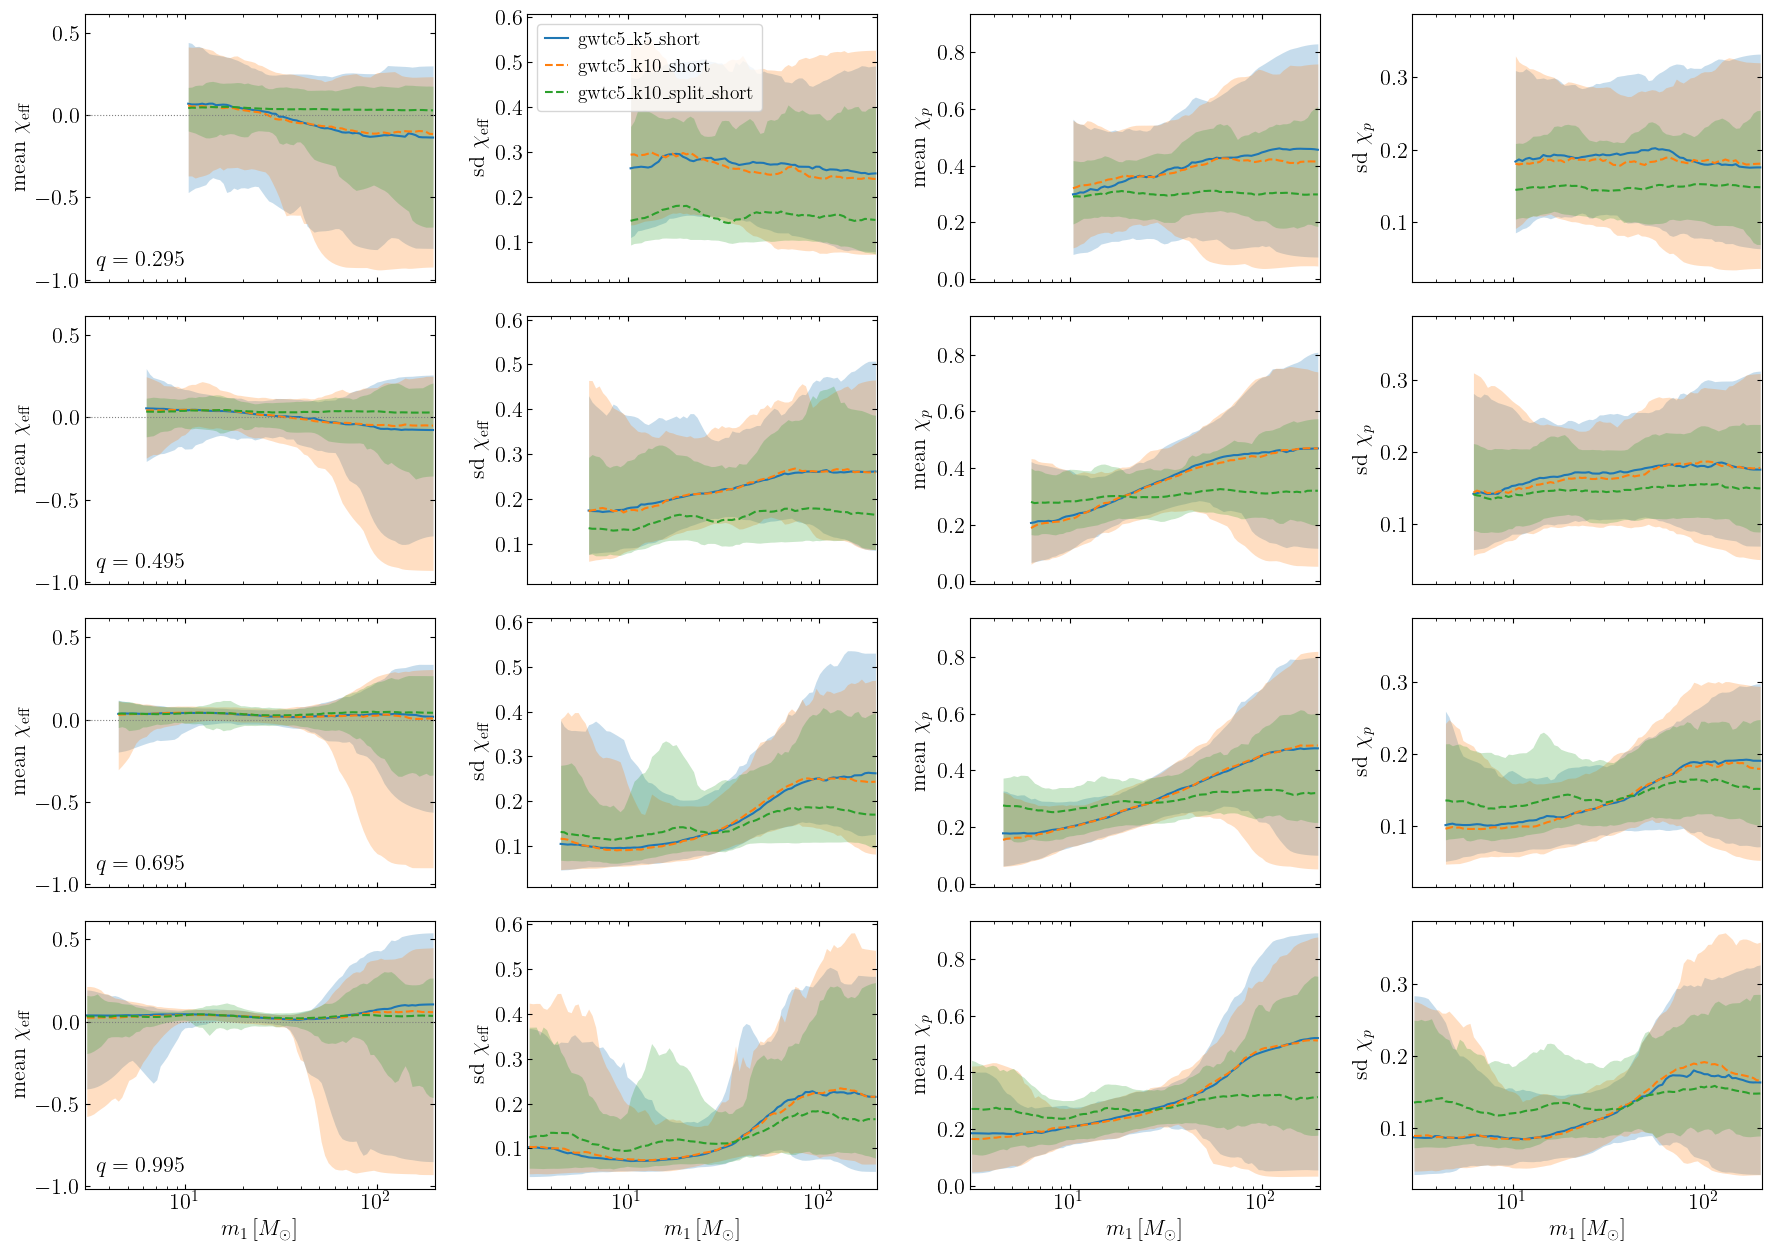

In [11]:
Q_SLICES = (0.3, 0.5, 0.7, 1.0)
fig, axes = plt.subplots(len(Q_SLICES), 4, figsize=(18, 3.2 * len(Q_SLICES)), sharex=True, sharey='col')
for rr, qv in enumerate(Q_SLICES):
    iq = int(np.argmin(np.abs(A.q_c - qv)))
    for run in RUNS:
        moment_panels(axes[rr], run, iq, label=LAB[run])
    axes[rr, 0].text(0.03, 0.06, rf'$q = {A.q_c[iq]:.3f}$', transform=axes[rr, 0].transAxes)
    axes[rr, 0].axhline(0, color='0.5', lw=0.8, ls=':')
for c, lab in enumerate(MOM_LABELS):
    axes[-1, c].set_xlabel(r'$m_1\,[M_\odot]$')
    for rr in range(len(Q_SLICES)):
        axes[rr, c].set_ylabel(lab)
axes[0, 0].set_xscale('log'); axes[0, 0].set_xlim(A.MIN_M, A.MAX_M)
axes[0, 1].legend(loc='upper left', **plot_style.LEG_KW)
fig.tight_layout(); plot_style.save(fig, f'compare_{NAME}_spin_moments_q_slices')

## Spin distributions at fixed primary mass

$p(\chi_\mathrm{eff} \mid m_1)$ and $p(\chi_p \mid m_1)$ in the $m_1$ bin nearest each mass, averaged over $q$ with
the windowed $p(q \mid m_1)$ (so the low-$q$ corner excluded by $m_2 > 3\,M_\odot$ does not contribute). Log $y$ axes,
so the tails show.

Saved /home/jack.heinzel/public_html/bbh-pixelpop-constraints/plots/compare_gwtc5_field_vs_split_chieff_given_m1.pdf


Saved /home/jack.heinzel/public_html/bbh-pixelpop-constraints/plots/compare_gwtc5_field_vs_split_chip_given_m1.pdf


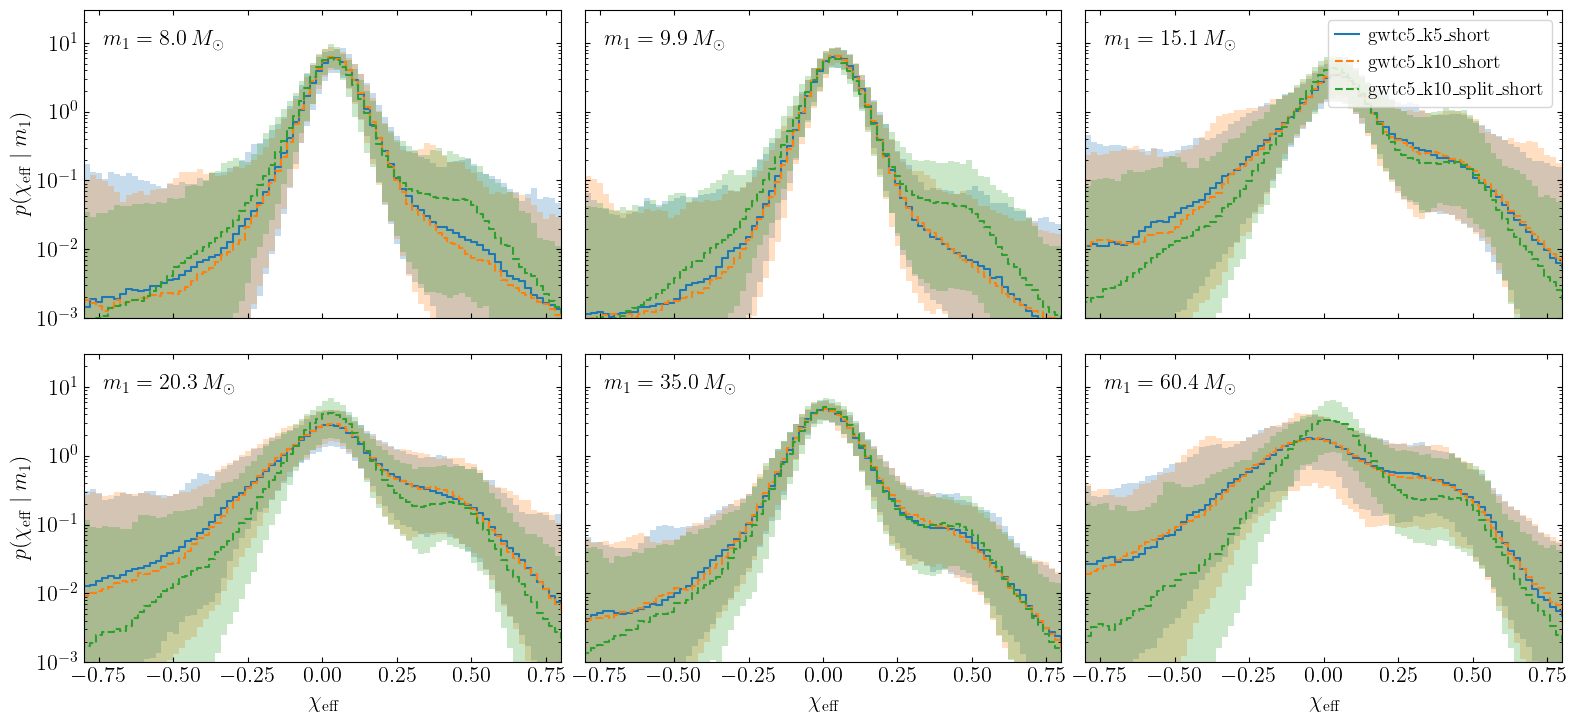

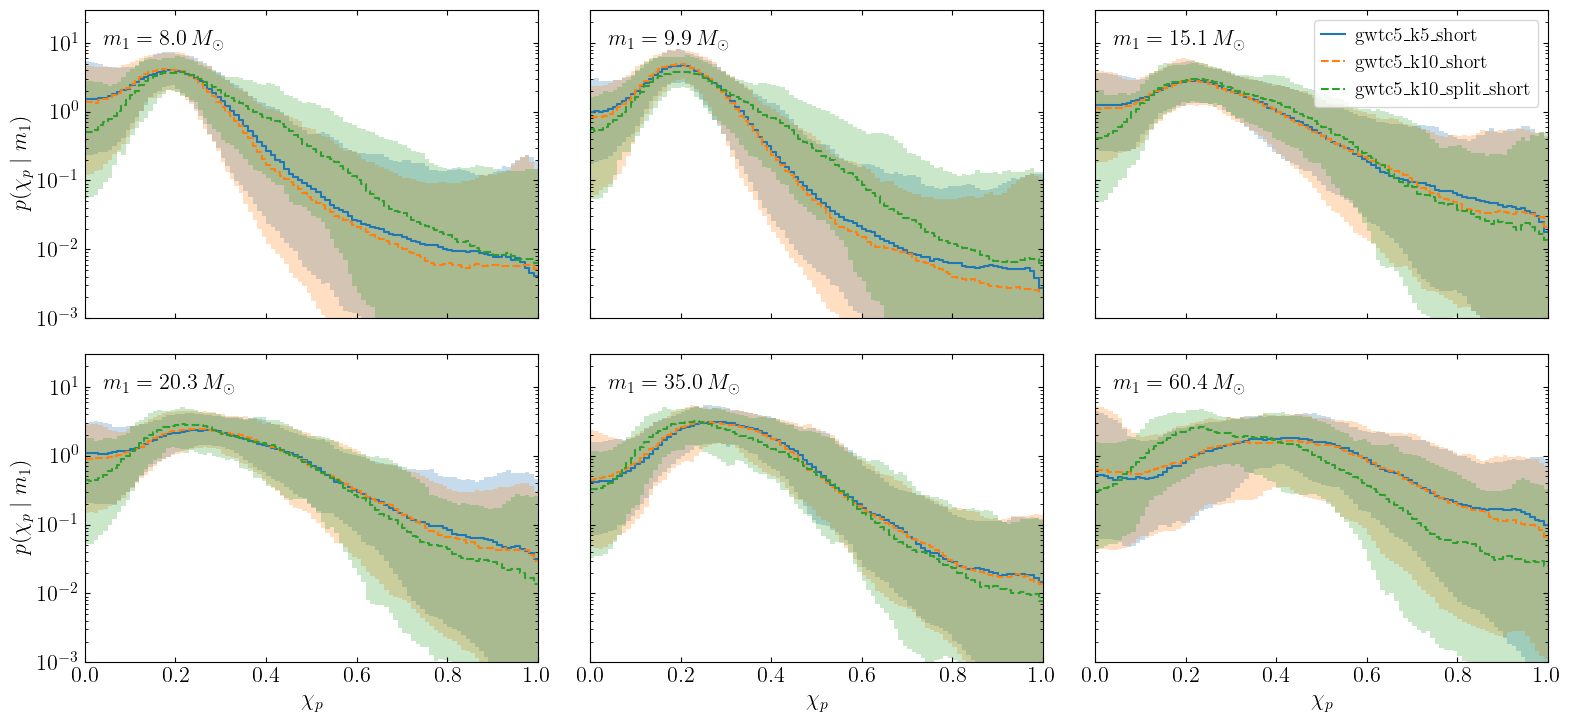

In [12]:
M_SEL = (8., 10., 15., 20., 35., 60.)
for key, edges, d, lab, xlim, nm in (('PE_M', A.e_edges, A.de, r'\chi_\mathrm{eff}', (-0.8, 0.8), 'chieff'),
                                     ('PP_M', A.p_edges, A.dp, r'\chi_p', (0., 1.), 'chip')):
    fig, axes = plt.subplots(2, 3, figsize=(16, 7.5), sharex=True, sharey=True)
    for ax, m in zip(axes.ravel(), M_SEL):
        im = int(np.argmin(np.abs(A.m_c - m)))
        for run in RUNS:
            y = getattr(R[run], key)[:, im] / d
            lo, med, hi = band(np.concatenate([y, y[:, -1:]], 1))
            ax.fill_between(edges, np.maximum(lo, 1e-12), hi, step='post', color=COL[run], alpha=0.25, lw=0)
            ax.step(edges, med, where='post', color=COL[run], ls=LS[run], label=LAB[run])
        ax.text(0.04, 0.93, rf'$m_1 = {A.m_c[im]:.1f}\,M_\odot$', transform=ax.transAxes, va='top')
        ax.set_yscale('log'); ax.set_ylim(1e-3, 30); ax.set_xlim(*xlim)
    for ax in axes[-1]:
        ax.set_xlabel(rf'${lab}$')
    for ax in axes[:, 0]:
        ax.set_ylabel(rf'$p({lab} \mid m_1)$')
    axes[0, -1].legend(loc='upper right', **plot_style.LEG_KW)
    fig.tight_layout(); plot_style.save(fig, f'compare_{NAME}_{nm}_given_m1')

In [13]:
# how much does the spin distribution change between 10 and 60 Msun (q ~ 1), per run?
i10, i60 = (int(np.argmin(np.abs(A.m_c - m))) for m in (10., 60.))
rows = {}
for k, nm in enumerate(A.MOM_NAMES):
    for run in RUNS:
        d = R[run].MOM[:, i60, -1, k] - R[run].MOM[:, i10, -1, k]
        rows.setdefault(f'{nm}: 60 minus 10 Msun', {})[run] = fmt(d) + f'; P(> 0) {np.mean(d > 0):.2f}'
pd.DataFrame(rows).T

,ppc_gwtc5_k5_short,ppc_gwtc5_k10_short,ppc_gwtc5_k10_split_short
mean chi_eff: 60 minus 10 Msun,"-0.023 [-0.389, 0.232]; P(> 0) 0.41","-0.010 [-0.938, 0.173]; P(> 0) 0.45","-0.002 [-0.146, 0.093]; P(> 0) 0.47"
sd chi_eff: 60 minus 10 Msun,"0.106 [-0.117, 0.303]; P(> 0) 0.87","0.096 [-0.018, 0.311]; P(> 0) 0.90","0.049 [-0.021, 0.205]; P(> 0) 0.84"
mean chi_p: 60 minus 10 Msun,"0.162 [-0.102, 0.388]; P(> 0) 0.91","0.158 [-0.126, 0.345]; P(> 0) 0.92","0.056 [-0.022, 0.238]; P(> 0) 0.85"
sd chi_p: 60 minus 10 Msun,"0.066 [-0.029, 0.189]; P(> 0) 0.91","0.075 [-0.017, 0.181]; P(> 0) 0.91","0.025 [-0.019, 0.120]; P(> 0) 0.81"
